In [1]:

# ============================================================
# RQ3 - STEP 6.1A: SKILL PREVALENCE AND DATA COVERAGE
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# 1. Define paths
DATA_DIR = Path(r"E:\Analytic Plan BI\LinkedIn Dataset")
OUTPUT_DIR = DATA_DIR / "Assignment_2_Analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load prepared datasets
us_ba_geo = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv"
)

skills_standard = pd.read_csv(
    OUTPUT_DIR / "US_BA_SKILLS_STANDARDISED.csv"
)

print("=" * 65)
print("RQ3 - SKILL DATASET VALIDATION")
print("=" * 65)

print("\nJob dataset shape:", us_ba_geo.shape)
print("Skills dataset shape:", skills_standard.shape)

print("\nSkills dataset columns:")
print(skills_standard.columns.tolist())

# 3. Check required columns
required_columns = {"job_link", "skill_standard"}

missing_columns = (
    required_columns - set(skills_standard.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# 4. Standardise identifiers and remove invalid rows
us_ba_geo["job_link"] = (
    us_ba_geo["job_link"].astype("string").str.strip()
)

skills_standard["job_link"] = (
    skills_standard["job_link"].astype("string").str.strip()
)

skills_standard["skill_standard"] = (
    skills_standard["skill_standard"]
    .astype("string")
    .str.strip()
    .str.lower()
)

skills_standard = skills_standard.dropna(
    subset=["job_link", "skill_standard"]
)

skills_standard = skills_standard.loc[
    skills_standard["job_link"].ne("")
    & skills_standard["skill_standard"].ne("")
].copy()

# 5. Restrict skills to the fixed RQ1/RQ2 BA cohort
ba_links = set(
    us_ba_geo["job_link"].dropna().unique()
)

skills_standard = skills_standard.loc[
    skills_standard["job_link"].isin(ba_links)
].copy()

# 6. Ensure each skill appears only once per advertisement
skills_standard = skills_standard.drop_duplicates(
    subset=["job_link", "skill_standard"]
)

# 7. Calculate coverage
total_ba_jobs = us_ba_geo["job_link"].nunique()

jobs_with_skills = (
    skills_standard["job_link"].nunique()
)

coverage_pct = (
    jobs_with_skills / total_ba_jobs * 100
)

missing_skill_jobs = (
    total_ba_jobs - jobs_with_skills
)

print("\nDATA COVERAGE")
print("Total BA advertisements:", total_ba_jobs)
print("BA advertisements with skills:", jobs_with_skills)
print("BA advertisements without skills:", missing_skill_jobs)
print("Skills coverage (%):", round(coverage_pct, 2))

# 8. Calculate skill prevalence
skill_prevalence = (
    skills_standard
    .groupby("skill_standard")["job_link"]
    .nunique()
    .reset_index(name="Advertisements")
    .sort_values(
        ["Advertisements", "skill_standard"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

skill_prevalence["Prevalence_Pct"] = (
    skill_prevalence["Advertisements"]
    / jobs_with_skills
    * 100
)

# 9. Add rank
skill_prevalence.insert(
    0,
    "Rank",
    np.arange(1, len(skill_prevalence) + 1)
)

print("\nSKILL SUMMARY")
print(
    "Unique standardised skills:",
    skill_prevalence["skill_standard"].nunique()
)

print(
    "Unique job-skill pairs:",
    len(skills_standard)
)

print("\nTOP 30 REQUESTED SKILLS:")
display(
    skill_prevalence.head(30).round(2)
)

# 10. Summary statistics for skills per advertisement
skills_per_job = (
    skills_standard
    .groupby("job_link")["skill_standard"]
    .nunique()
)

print("\nSKILLS PER ADVERTISEMENT")
print("Mean:", round(skills_per_job.mean(), 2))
print("Median:", skills_per_job.median())
print("Standard deviation:", round(skills_per_job.std(), 2))
print("Minimum:", skills_per_job.min())
print("Maximum:", skills_per_job.max())

# 11. Save results
skill_prevalence.to_csv(
    OUTPUT_DIR / "RQ3_SKILL_PREVALENCE.csv",
    index=False
)

skills_per_job.rename(
    "Skill_Count"
).reset_index().to_csv(
    OUTPUT_DIR / "RQ3_SKILLS_PER_ADVERTISEMENT.csv",
    index=False
)

print("\nRQ3 Step 6.1A results saved successfully.")


RQ3 - SKILL DATASET VALIDATION

Job dataset shape: (3722, 12)
Skills dataset shape: (92020, 5)

Skills dataset columns:
['job_link', 'job_skills', 'skill', 'skill_clean', 'skill_standard']

DATA COVERAGE
Total BA advertisements: 3722
BA advertisements with skills: 3606
BA advertisements without skills: 116
Skills coverage (%): 96.88

SKILL SUMMARY
Unique standardised skills: 22189
Unique job-skill pairs: 92020

TOP 30 REQUESTED SKILLS:


,Rank,skill_standard,Advertisements,Prevalence_Pct
0,1,business analysis,1475,40.90
1,2,project management,1232,34.17
2,3,data analysis,1214,33.67
3,4,communication,1069,29.65
4,5,problem solving,974,27.01
5,6,sql,916,25.40
6,7,analytical skills,750,20.80
7,8,communication skills,591,16.39
8,9,requirements gathering,576,15.97
9,10,teamwork,574,15.92



SKILLS PER ADVERTISEMENT
Mean: 25.52
Median: 22.0
Standard deviation: 15.54
Minimum: 1
Maximum: 159

RQ3 Step 6.1A results saved successfully.


RQ3 - WILSON 95% CONFIDENCE INTERVALS
Advertisements with skills: 3606


,Rank,skill_standard,Advertisements,Prevalence_Pct,CI_Lower_Pct,CI_Upper_Pct
0,1,business analysis,1475,40.90,39.31,42.52
1,2,project management,1232,34.17,32.63,35.73
2,3,data analysis,1214,33.67,32.14,35.23
3,4,communication,1069,29.65,28.18,31.16
4,5,problem solving,974,27.01,25.59,28.48
5,6,sql,916,25.40,24.01,26.85
6,7,analytical skills,750,20.80,19.51,22.15
7,8,communication skills,591,16.39,15.22,17.63
8,9,requirements gathering,576,15.97,14.81,17.21
9,10,teamwork,574,15.92,14.76,17.15


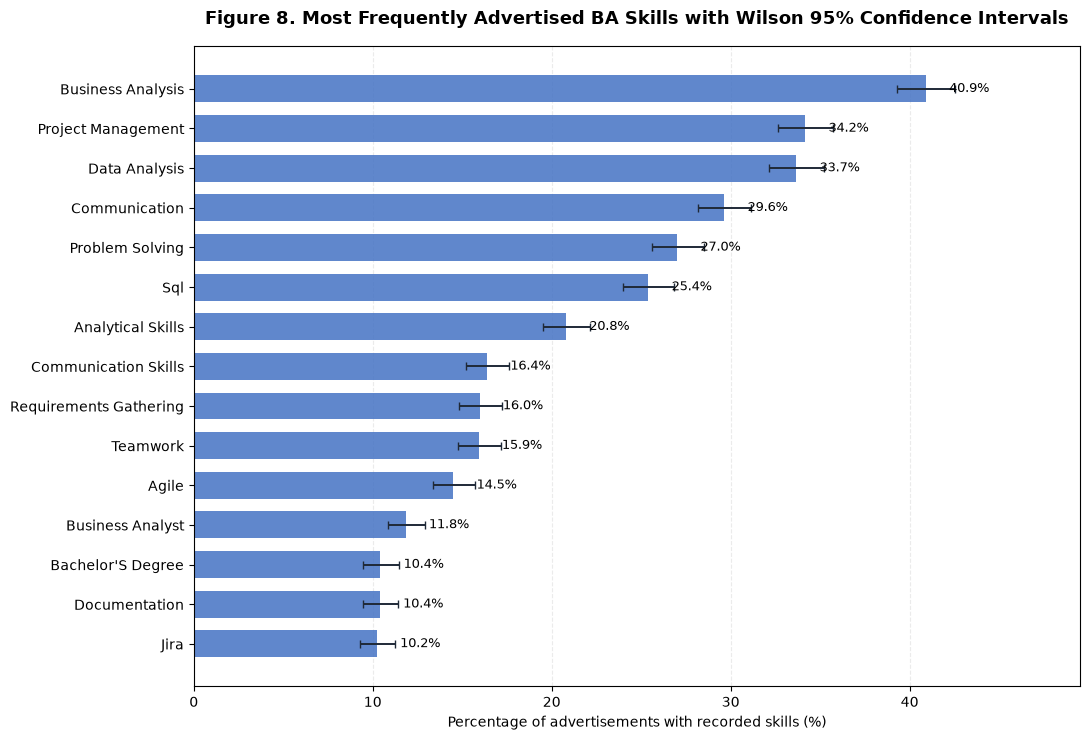


Figure 8 and Wilson interval results saved.


In [2]:

# ============================================================
# RQ3 - STEP 6.1B: WILSON 95% CONFIDENCE INTERVALS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

# 1. Use results from Step 6.1A
rq3_wilson = skill_prevalence.copy()

n = int(jobs_with_skills)

assert n == 3606
assert rq3_wilson["Advertisements"].between(0, n).all()

# 2. Calculate Wilson score confidence intervals
lower, upper = proportion_confint(
    count=rq3_wilson["Advertisements"].to_numpy(),
    nobs=n,
    alpha=0.05,
    method="wilson"
)

rq3_wilson["CI_Lower_Pct"] = lower * 100
rq3_wilson["CI_Upper_Pct"] = upper * 100

rq3_wilson["CI_Width_Pct"] = (
    rq3_wilson["CI_Upper_Pct"]
    - rq3_wilson["CI_Lower_Pct"]
)

# 3. Display top 20
print("=" * 65)
print("RQ3 - WILSON 95% CONFIDENCE INTERVALS")
print("=" * 65)

print("Advertisements with skills:", n)

display(
    rq3_wilson[
        [
            "Rank",
            "skill_standard",
            "Advertisements",
            "Prevalence_Pct",
            "CI_Lower_Pct",
            "CI_Upper_Pct"
        ]
    ].head(20).round(2)
)

# 4. Figure 8: Top 15 skills with Wilson intervals
top15 = rq3_wilson.head(15).iloc[::-1].copy()

y = np.arange(len(top15))

x_values = top15["Prevalence_Pct"].to_numpy()

x_errors = np.vstack([
    x_values - top15["CI_Lower_Pct"].to_numpy(),
    top15["CI_Upper_Pct"].to_numpy() - x_values
])

fig, ax = plt.subplots(figsize=(11, 7.5))

ax.barh(
    y,
    x_values,
    color="#4472C4",
    alpha=0.85,
    height=0.68
)

ax.errorbar(
    x_values,
    y,
    xerr=x_errors,
    fmt="none",
    ecolor="#1F2937",
    elinewidth=1.4,
    capsize=3
)

ax.set_yticks(y)
ax.set_yticklabels(
    top15["skill_standard"].str.title(),
    fontsize=10
)

ax.set_xlabel(
    "Percentage of advertisements with recorded skills (%)"
)

ax.set_title(
    "Figure 8. Most Frequently Advertised BA Skills "
    "with Wilson 95% Confidence Intervals",
    fontsize=13,
    fontweight="bold",
    pad=16
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.set_xlim(
    0,
    top15["CI_Upper_Pct"].max() + 7
)

for i, value in enumerate(x_values):
    ax.text(
        value + 1.3,
        i,
        f"{value:.1f}%",
        va="center",
        fontsize=9
    )

plt.tight_layout()

figure_path = (
    OUTPUT_DIR / "RQ3_Figure_8_Skill_Prevalence_Wilson_CI.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Save complete confidence interval table
rq3_wilson.to_csv(
    OUTPUT_DIR / "RQ3_SKILL_PREVALENCE_WILSON_CI.csv",
    index=False
)

print("\nFigure 8 and Wilson interval results saved.")


In [3]:

# ============================================================
# RQ3 - STEP 6.2A: SKILL CATEGORY ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

# Explicit, auditable mapping of selected skill labels.
# This is not a classification of all 22,189 labels.

category_mapping = {
    # Business analysis and requirements
    "business analysis": "Business Analysis & Requirements",
    "requirements gathering": "Business Analysis & Requirements",
    "business requirements": "Business Analysis & Requirements",
    "functional specifications": "Business Analysis & Requirements",
    "stakeholder management": "Business Analysis & Requirements",
    "user stories": "Business Analysis & Requirements",
    "documentation": "Business Analysis & Requirements",

    # Data and technical
    "data analysis": "Data & Technical",
    "sql": "Data & Technical",
    "excel": "Data & Technical",
    "tableau": "Data & Technical",
    "data visualization": "Data & Technical",
    "reporting": "Data & Technical",
    "testing": "Data & Technical",

    # Project delivery and tools
    "project management": "Project Delivery & Tools",
    "agile": "Project Delivery & Tools",
    "jira": "Project Delivery & Tools",

    # Communication and collaboration
    "communication": "Communication & Collaboration",
    "communication skills": "Communication & Collaboration",
    "teamwork": "Communication & Collaboration",
    "collaboration": "Communication & Collaboration",
    "interpersonal skills": "Communication & Collaboration",

    # Analytical and problem-solving
    "problem solving": "Analytical & Problem-Solving",
    "analytical skills": "Analytical & Problem-Solving",
    "attention to detail": "Analytical & Problem-Solving",

    # Excluded from competency analysis
    "business analyst": "Role / Qualification",
    "bachelor's degree": "Role / Qualification",
    "computer science": "Role / Qualification"
}

# 1. Map selected labels
rq3_categorised = skills_standard[
    ["job_link", "skill_standard"]
].copy()

rq3_categorised["Skill_Category"] = (
    rq3_categorised["skill_standard"]
    .map(category_mapping)
)

# 2. Count mapping coverage
mapped_pairs = rq3_categorised[
    "Skill_Category"
].notna().sum()

print("=" * 65)
print("RQ3 - SKILL CATEGORY MAPPING COVERAGE")
print("=" * 65)

print("Total job-skill pairs:", len(rq3_categorised))
print("Mapped job-skill pairs:", mapped_pairs)
print(
    "Mapped pair coverage:",
    f"{mapped_pairs / len(rq3_categorised) * 100:.2f}%"
)

# 3. Restrict to actual competency categories
competency_data = rq3_categorised.loc[
    rq3_categorised["Skill_Category"].notna()
    & rq3_categorised["Skill_Category"].ne(
        "Role / Qualification"
    )
].copy()

# 4. Deduplicate within advertisement and category
job_category = competency_data.drop_duplicates(
    subset=["job_link", "Skill_Category"]
)

# 5. Calculate category-level prevalence
category_prevalence = (
    job_category
    .groupby("Skill_Category")["job_link"]
    .nunique()
    .reset_index(name="Advertisements")
    .sort_values("Advertisements", ascending=False)
)

category_prevalence["Prevalence_Pct"] = (
    category_prevalence["Advertisements"]
    / jobs_with_skills
    * 100
)

print("\nCATEGORY PREVALENCE:")
display(category_prevalence.round(2))

# 6. Calculate number of mapped competency categories per job
categories_per_job = (
    job_category
    .groupby("job_link")["Skill_Category"]
    .nunique()
)

print("\nNUMBER OF MAPPED COMPETENCY CATEGORIES PER JOB:")
print("Mean:", round(categories_per_job.mean(), 2))
print("Median:", categories_per_job.median())
print("Maximum:", categories_per_job.max())

print("\nADVERTISEMENTS WITH AT LEAST ONE MAPPED COMPETENCY:")
print(categories_per_job.size)
print(
    "Coverage:",
    f"{categories_per_job.size / jobs_with_skills * 100:.2f}%"
)

# 7. Save results
category_prevalence.to_csv(
    OUTPUT_DIR / "RQ3_CATEGORY_PREVALENCE.csv",
    index=False
)

job_category.to_csv(
    OUTPUT_DIR / "RQ3_JOB_CATEGORY_PAIRS.csv",
    index=False
)

print("\nStep 6.2A results saved successfully.")


RQ3 - SKILL CATEGORY MAPPING COVERAGE
Total job-skill pairs: 92020
Mapped job-skill pairs: 15389
Mapped pair coverage: 16.72%

CATEGORY PREVALENCE:


,Skill_Category,Advertisements,Prevalence_Pct
1,Business Analysis & Requirements,2163,59.98
3,Data & Technical,2043,56.66
2,Communication & Collaboration,1970,54.63
4,Project Delivery & Tools,1735,48.11
0,Analytical & Problem-Solving,1537,42.62



NUMBER OF MAPPED COMPETENCY CATEGORIES PER JOB:
Mean: 2.82
Median: 3.0
Maximum: 5

ADVERTISEMENTS WITH AT LEAST ONE MAPPED COMPETENCY:
3348
Coverage: 92.85%

Step 6.2A results saved successfully.


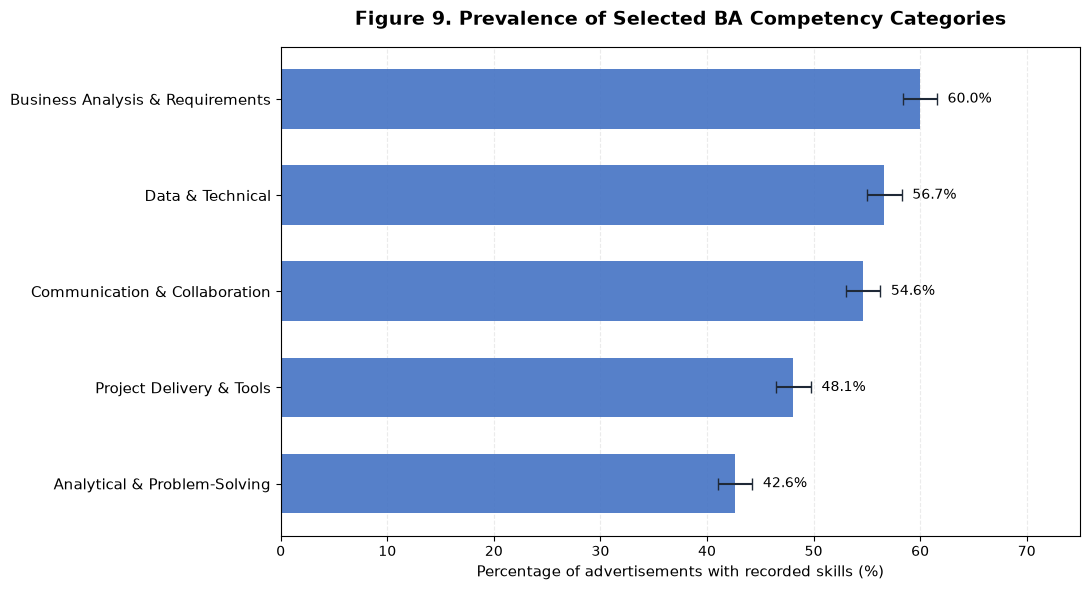

Figure 9 and category confidence intervals saved.


In [4]:

# ============================================================
# RQ3 - STEP 6.2B: CATEGORY PREVALENCE VISUALISATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

# 1. Prepare category results
category_plot = (
    category_prevalence
    .sort_values("Prevalence_Pct", ascending=True)
    .copy()
)

n = int(jobs_with_skills)

# 2. Wilson confidence intervals
lower, upper = proportion_confint(
    count=category_plot["Advertisements"].to_numpy(),
    nobs=n,
    alpha=0.05,
    method="wilson"
)

category_plot["CI_Lower_Pct"] = lower * 100
category_plot["CI_Upper_Pct"] = upper * 100

# 3. Plot
fig, ax = plt.subplots(figsize=(11, 6))

y = np.arange(len(category_plot))
values = category_plot["Prevalence_Pct"].to_numpy()

errors = np.vstack([
    values - category_plot["CI_Lower_Pct"].to_numpy(),
    category_plot["CI_Upper_Pct"].to_numpy() - values
])

bars = ax.barh(
    y,
    values,
    color="#4472C4",
    height=0.62,
    alpha=0.9
)

ax.errorbar(
    values,
    y,
    xerr=errors,
    fmt="none",
    ecolor="#1F2937",
    capsize=4,
    elinewidth=1.5
)

ax.set_yticks(y)
ax.set_yticklabels(
    category_plot["Skill_Category"],
    fontsize=11
)

ax.set_xlabel(
    "Percentage of advertisements with recorded skills (%)",
    fontsize=11
)

ax.set_title(
    "Figure 9. Prevalence of Selected BA Competency Categories",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Leave space for labels beyond the CI whiskers
ax.set_xlim(0, 75)

for i, (_, row) in enumerate(category_plot.iterrows()):
    ax.text(
        row["CI_Upper_Pct"] + 1,
        i,
        f"{row['Prevalence_Pct']:.1f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()

figure_path = (
    OUTPUT_DIR / "RQ3_Figure_9_Competency_Categories.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 4. Save results with confidence intervals
category_plot.to_csv(
    OUTPUT_DIR / "RQ3_CATEGORY_PREVALENCE_WILSON_CI.csv",
    index=False
)

print("Figure 9 and category confidence intervals saved.")


In [5]:

# ============================================================
# RQ3 - STEP 6.3A: SKILL CO-OCCURRENCE AND ASSOCIATION
# ============================================================

import pandas as pd
import numpy as np
from itertools import combinations

# 1. Select top 30 skills
top_skills = (
    skill_prevalence
    .head(30)["skill_standard"]
    .tolist()
)

# 2. Restrict to selected skills
association_data = skills_standard.loc[
    skills_standard["skill_standard"].isin(top_skills),
    ["job_link", "skill_standard"]
].drop_duplicates()

# 3. Construct binary advertisement-skill matrix
skill_matrix = pd.crosstab(
    association_data["job_link"],
    association_data["skill_standard"]
).gt(0)

# Include advertisements with no top-30 skill
skill_matrix = skill_matrix.reindex(
    index=us_ba_geo.loc[
        us_ba_geo["job_link"].isin(
            skills_standard["job_link"]
        ),
        "job_link"
    ].drop_duplicates(),
    fill_value=False
)

n_jobs = len(skill_matrix)

assert n_jobs == 3606

# 4. Skill occurrence counts
skill_counts = skill_matrix.sum(axis=0)

# 5. Calculate pairwise associations
results = []

for skill_a, skill_b in combinations(top_skills, 2):

    a = skill_matrix[skill_a]
    b = skill_matrix[skill_b]

    count_a = int(a.sum())
    count_b = int(b.sum())
    count_ab = int((a & b).sum())

    support_a = count_a / n_jobs
    support_b = count_b / n_jobs
    support_ab = count_ab / n_jobs

    confidence_a_to_b = (
        count_ab / count_a
        if count_a > 0 else np.nan
    )

    confidence_b_to_a = (
        count_ab / count_b
        if count_b > 0 else np.nan
    )

    lift = (
        support_ab / (support_a * support_b)
        if support_a * support_b > 0
        else np.nan
    )

    results.append({
        "Skill_A": skill_a,
        "Skill_B": skill_b,
        "Count_A": count_a,
        "Count_B": count_b,
        "Cooccurrence_Count": count_ab,
        "Support_Pct": support_ab * 100,
        "Confidence_A_to_B_Pct": confidence_a_to_b * 100,
        "Confidence_B_to_A_Pct": confidence_b_to_a * 100,
        "Lift": lift
    })

associations = pd.DataFrame(results)

# 6. Apply minimum support threshold
# At least 2% of advertisements must contain both skills.
min_support_pct = 2.0

associations_filtered = associations.loc[
    associations["Support_Pct"] >= min_support_pct
].copy()

# 7. Rank by lift, with co-occurrence as tie-breaker
associations_filtered = associations_filtered.sort_values(
    ["Lift", "Cooccurrence_Count"],
    ascending=[False, False]
).reset_index(drop=True)

print("=" * 65)
print("RQ3 - SKILL ASSOCIATION ANALYSIS")
print("=" * 65)

print("Advertisements analysed:", n_jobs)
print("Selected skills:", len(top_skills))
print("Total skill pairs tested:", len(associations))
print(
    "Pairs meeting 2% support:",
    len(associations_filtered)
)

print("\nTOP 20 ASSOCIATIONS BY LIFT:")

display(
    associations_filtered[
        [
            "Skill_A",
            "Skill_B",
            "Cooccurrence_Count",
            "Support_Pct",
            "Confidence_A_to_B_Pct",
            "Confidence_B_to_A_Pct",
            "Lift"
        ]
    ].head(20).round(3)
)

# 8. Most common combinations by raw support
print("\nTOP 20 ASSOCIATIONS BY SUPPORT:")

display(
    associations_filtered.sort_values(
        ["Support_Pct", "Lift"],
        ascending=False
    )[
        [
            "Skill_A",
            "Skill_B",
            "Cooccurrence_Count",
            "Support_Pct",
            "Lift"
        ]
    ].head(20).round(3)
)

# 9. Save results
associations.to_csv(
    OUTPUT_DIR / "RQ3_ALL_TOP30_SKILL_ASSOCIATIONS.csv",
    index=False
)

associations_filtered.to_csv(
    OUTPUT_DIR / "RQ3_FILTERED_SKILL_ASSOCIATIONS.csv",
    index=False
)

print("\nAssociation analysis saved successfully.")


RQ3 - SKILL ASSOCIATION ANALYSIS
Advertisements analysed: 3606
Selected skills: 30
Total skill pairs tested: 435
Pairs meeting 2% support: 197

TOP 20 ASSOCIATIONS BY LIFT:


,Skill_A,Skill_B,Cooccurrence_Count,Support_Pct,Confidence_A_to_B_Pct,Confidence_B_to_A_Pct,Lift
0,data visualization,tableau,125,3.466,45.126,46.642,6.072
1,teamwork,multitasking,192,5.324,33.449,64.646,4.061
2,multitasking,functional specifications,77,2.135,25.926,29.167,3.541
3,excel,tableau,96,2.662,26.087,35.821,3.510
4,jira,user stories,97,2.690,26.287,33.333,3.257
5,analytical skills,multitasking,187,5.186,24.933,62.963,3.027
6,sql,tableau,196,5.435,21.397,73.134,2.879
7,excel,data visualization,80,2.219,21.739,28.881,2.830
8,documentation,testing,95,2.634,25.333,27.859,2.679
9,agile,jira,124,3.439,23.709,33.604,2.317



TOP 20 ASSOCIATIONS BY SUPPORT:


,Skill_A,Skill_B,Cooccurrence_Count,Support_Pct,Lift
101,business analysis,project management,631,17.499,1.252
21,communication,problem solving,577,16.001,1.998
103,business analysis,communication,540,14.975,1.235
61,project management,communication,532,14.753,1.457
52,data analysis,sql,489,13.561,1.586
167,business analysis,data analysis,483,13.394,0.973
122,project management,data analysis,481,13.339,1.160
113,business analysis,problem solving,479,13.283,1.202
67,project management,problem solving,470,13.034,1.412
97,data analysis,communication,461,12.784,1.281



Association analysis saved successfully.


In [6]:

# ============================================================
# RQ3 - STEP 6.3B: FISHER EXACT TEST + HOLM CORRECTION
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

# 1. Use the binary matrix from Step 6.3A
assert len(skill_matrix) == 3606
assert len(associations) == 435

n = len(skill_matrix)

# 2. Calculate Fisher exact tests for all pairs
test_results = []

for _, row in associations.iterrows():

    a = skill_matrix[row["Skill_A"]].astype(bool)
    b = skill_matrix[row["Skill_B"]].astype(bool)

    both = int((a & b).sum())
    a_only = int((a & ~b).sum())
    b_only = int((~a & b).sum())
    neither = int((~a & ~b).sum())

    contingency = [
        [both, a_only],
        [b_only, neither]
    ]

    odds_ratio, p_value = fisher_exact(
        contingency,
        alternative="two-sided"
    )

    test_results.append({
        "Skill_A": row["Skill_A"],
        "Skill_B": row["Skill_B"],
        "Odds_Ratio": odds_ratio,
        "P_Value": p_value
    })

test_df = pd.DataFrame(test_results)

# 3. Merge with association metrics
association_tests = associations.merge(
    test_df,
    on=["Skill_A", "Skill_B"],
    how="left",
    validate="one_to_one"
)

# 4. Holm correction across ALL 435 tests
reject, p_adjusted, _, _ = multipletests(
    association_tests["P_Value"],
    alpha=0.05,
    method="holm"
)

association_tests["Holm_P"] = p_adjusted
association_tests["Holm_Significant"] = reject

# 5. Classify association direction
association_tests["Direction"] = np.select(
    [
        association_tests["Lift"] > 1,
        association_tests["Lift"] < 1
    ],
    [
        "Positive",
        "Negative"
    ],
    default="Neutral"
)

# 6. Summary of all tests
print("=" * 65)
print("RQ3 - SKILL ASSOCIATION SIGNIFICANCE TESTING")
print("=" * 65)

print("Total tests:", len(association_tests))

print(
    "Significant after Holm correction:",
    int(association_tests["Holm_Significant"].sum())
)

print(
    "Significant positive associations:",
    int(
        (
            association_tests["Holm_Significant"]
            & association_tests["Lift"].gt(1)
        ).sum()
    )
)

print(
    "Significant negative associations:",
    int(
        (
            association_tests["Holm_Significant"]
            & association_tests["Lift"].lt(1)
        ).sum()
    )
)

# 7. Focus on practically relevant positive associations
significant_positive = association_tests.loc[
    association_tests["Holm_Significant"]
    & association_tests["Lift"].gt(1)
    & association_tests["Support_Pct"].ge(2)
].copy()

significant_positive = significant_positive.sort_values(
    ["Lift", "Support_Pct"],
    ascending=False
)

print("\nSIGNIFICANT POSITIVE ASSOCIATIONS")
print("With support >= 2%:", len(significant_positive))

display(
    significant_positive[
        [
            "Skill_A",
            "Skill_B",
            "Cooccurrence_Count",
            "Support_Pct",
            "Lift",
            "Odds_Ratio",
            "P_Value",
            "Holm_P"
        ]
    ].head(20).round(5)
)

# 8. Examine high-support pairs that are not significant
high_support_nonsignificant = association_tests.loc[
    association_tests["Support_Pct"].ge(5)
    & ~association_tests["Holm_Significant"]
].sort_values(
    "Support_Pct",
    ascending=False
)

print("\nHIGH-SUPPORT PAIRS NOT SIGNIFICANT AFTER HOLM:")
display(
    high_support_nonsignificant[
        [
            "Skill_A",
            "Skill_B",
            "Support_Pct",
            "Lift",
            "Holm_P"
        ]
    ].head(15).round(5)
)

# 9. Save results
association_tests.to_csv(
    OUTPUT_DIR / "RQ3_SKILL_ASSOCIATIONS_FISHER_HOLM.csv",
    index=False
)

significant_positive.to_csv(
    OUTPUT_DIR / "RQ3_SIGNIFICANT_POSITIVE_SKILL_ASSOCIATIONS.csv",
    index=False
)

print("\nStatistical testing results saved successfully.")


RQ3 - SKILL ASSOCIATION SIGNIFICANCE TESTING
Total tests: 435
Significant after Holm correction: 130
Significant positive associations: 112
Significant negative associations: 18

SIGNIFICANT POSITIVE ASSOCIATIONS
With support >= 2%: 92


,Skill_A,Skill_B,Cooccurrence_Count,Support_Pct,Lift,Odds_Ratio,P_Value,Holm_P
430,data visualization,tableau,125,3.46644,6.07185,18.32214,0.0,0.0
236,teamwork,multitasking,192,5.32446,4.06124,14.01107,0.0,0.0
406,multitasking,functional specifications,77,2.13533,3.54125,5.84332,0.0,0.0
342,excel,tableau,96,2.66223,3.51006,6.29138,0.0,0.0
324,jira,user stories,97,2.68996,3.25745,5.59375,0.0,0.0
173,analytical skills,multitasking,187,5.18580,3.02726,8.29165,0.0,0.0
157,sql,tableau,196,5.43539,2.87907,9.89830,0.0,0.0
340,excel,data visualization,80,2.21852,2.83001,4.28793,0.0,0.0
302,documentation,testing,95,2.63450,2.67894,4.11694,0.0,0.0
248,agile,jira,124,3.43871,2.31696,3.59994,0.0,0.0



HIGH-SUPPORT PAIRS NOT SIGNIFICANT AFTER HOLM:


,Skill_A,Skill_B,Support_Pct,Lift,Holm_P
1,business analysis,data analysis,13.39434,0.97266,1.00000
4,business analysis,sql,9.65058,0.92879,1.00000
32,project management,sql,8.51359,0.98097,1.00000
85,communication,sql,8.48586,1.12687,1.00000
33,project management,analytical skills,7.62618,1.07321,1.00000
6,business analysis,communication skills,7.04382,1.05070,1.00000
34,project management,communication skills,6.68331,1.19356,0.07765
61,data analysis,communication skills,5.99002,1.08561,1.00000
36,project management,teamwork,5.99002,1.10143,1.00000
9,business analysis,agile,5.87909,0.99099,1.00000



Statistical testing results saved successfully.


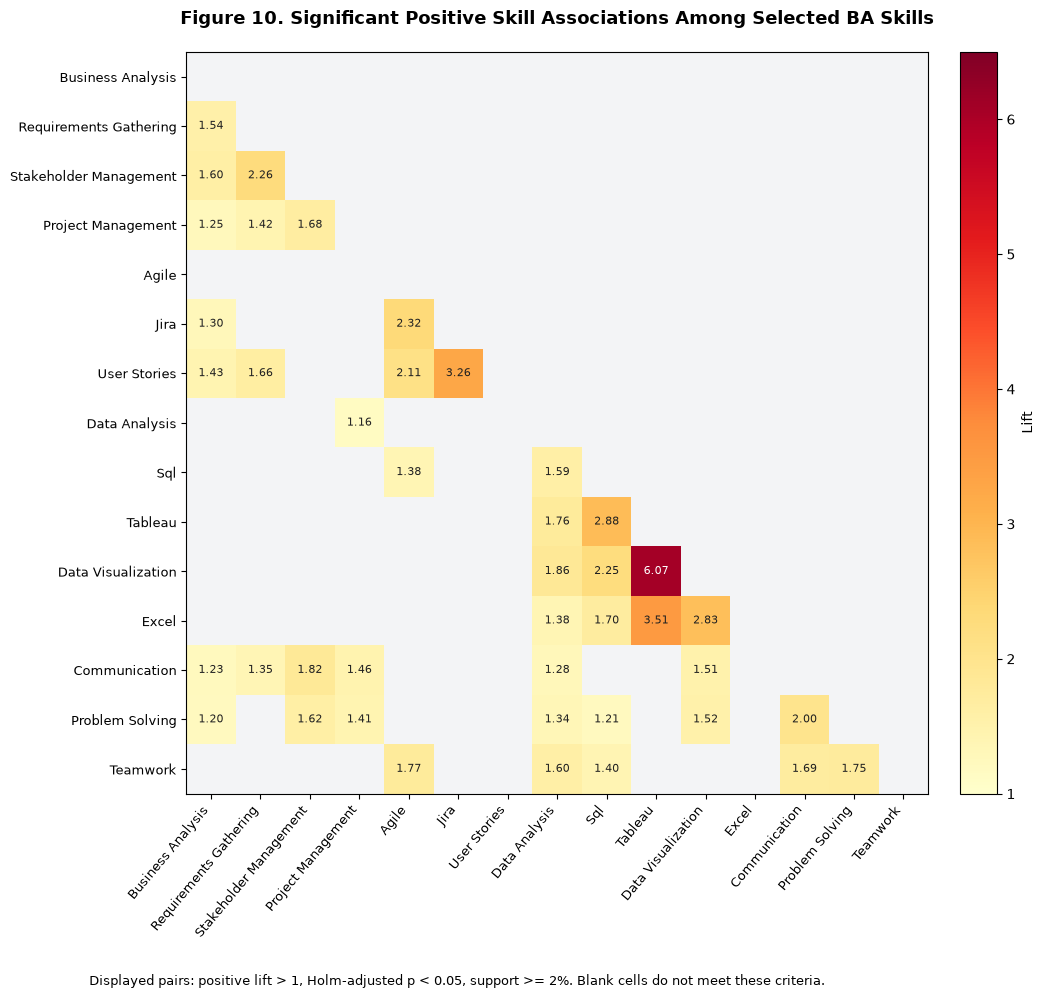

Figure 10 saved: E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\RQ3_Figure_10_Skill_Association_Heatmap.png
Significant positive pairs displayed: 42


In [7]:

# ============================================================
# RQ3 - STEP 6.3C: SIGNIFICANT SKILL ASSOCIATION HEATMAP
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# 1. Select interpretable skills from the tested top 30
selected_skills = [
    "business analysis",
    "requirements gathering",
    "stakeholder management",
    "project management",
    "agile",
    "jira",
    "user stories",
    "data analysis",
    "sql",
    "tableau",
    "data visualization",
    "excel",
    "communication",
    "problem solving",
    "teamwork"
]

# Validate that every skill was tested
available = set(skill_matrix.columns)
missing = set(selected_skills) - available

if missing:
    raise ValueError(f"Skills not found: {missing}")

# 2. Create matrices for lift and significance
n_skills = len(selected_skills)

lift_matrix = pd.DataFrame(
    np.nan,
    index=selected_skills,
    columns=selected_skills
)

significant_matrix = pd.DataFrame(
    False,
    index=selected_skills,
    columns=selected_skills
)

for _, row in association_tests.iterrows():
    a = row["Skill_A"]
    b = row["Skill_B"]

    if a not in selected_skills or b not in selected_skills:
        continue

    lift_matrix.loc[a, b] = row["Lift"]
    lift_matrix.loc[b, a] = row["Lift"]

    is_significant = (
        bool(row["Holm_Significant"])
        and row["Support_Pct"] >= 2
    )

    significant_matrix.loc[a, b] = is_significant
    significant_matrix.loc[b, a] = is_significant

# 3. Display only positive, significant associations
plot_matrix = lift_matrix.where(
    significant_matrix & lift_matrix.gt(1)
)

# Hide diagonal and duplicate upper triangle
mask = np.triu(
    np.ones((n_skills, n_skills), dtype=bool),
    k=0
)

plot_values = np.ma.masked_invalid(
    plot_matrix.to_numpy(dtype=float)
)

plot_values = np.ma.masked_where(
    mask,
    plot_values
)

# 4. Create heatmap
fig, ax = plt.subplots(figsize=(12, 10))

cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("#F3F4F6")

image = ax.imshow(
    plot_values,
    cmap=cmap,
    vmin=1,
    vmax=6.5,
    aspect="equal"
)

ax.set_xticks(np.arange(n_skills))
ax.set_yticks(np.arange(n_skills))

ax.set_xticklabels(
    [s.title() for s in selected_skills],
    rotation=50,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    [s.title() for s in selected_skills],
    fontsize=9
)

# 5. Annotate significant lift values
for i in range(n_skills):
    for j in range(i):
        value = plot_values[i, j]

        if np.ma.is_masked(value):
            continue

        ax.text(
            j,
            i,
            f"{float(value):.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color=(
                "white" if float(value) >= 4
                else "#202020"
            )
        )

# 6. Add title and legend
ax.set_title(
    "Figure 10. Significant Positive Skill Associations "
    "Among Selected BA Skills",
    fontsize=13,
    fontweight="bold",
    pad=20
)

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.045,
    pad=0.03
)

colorbar.set_label("Lift")

fig.text(
    0.5,
    0.01,
    "Displayed pairs: positive lift > 1, "
    "Holm-adjusted p < 0.05, support >= 2%. "
    "Blank cells do not meet these criteria.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

figure_path = (
    OUTPUT_DIR / "RQ3_Figure_10_Skill_Association_Heatmap.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Save plotted values
plot_matrix.to_csv(
    OUTPUT_DIR / "RQ3_SKILL_ASSOCIATION_HEATMAP_VALUES.csv"
)

print("Figure 10 saved:", figure_path)
print(
    "Significant positive pairs displayed:",
    int(np.sum(~plot_values.mask))
)


In [8]:

# ============================================================
# RQ3 - STEP 6.3D: SKILL ASSOCIATION ROBUSTNESS CHECK
# EXCLUDING THE LARGEST ADVERTISER
# ============================================================

import pandas as pd
import numpy as np
from itertools import combinations
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

# 1. Identify the largest advertiser
largest_advertiser = "LATICRETE International"

company_lookup = us_ba_geo[
    ["job_link", "company"]
].drop_duplicates(subset=["job_link"]).copy()

company_lookup["company"] = (
    company_lookup["company"]
    .fillna("")
    .astype(str)
    .str.strip()
)

excluded_links = set(
    company_lookup.loc[
        company_lookup["company"].eq(largest_advertiser),
        "job_link"
    ]
)

# 2. Remove the advertiser from the existing skill matrix
robust_matrix = skill_matrix.loc[
    ~skill_matrix.index.isin(excluded_links)
].copy()

n_original = len(skill_matrix)
n_robust = len(robust_matrix)

print("=" * 65)
print("RQ3 - SKILL ASSOCIATION ROBUSTNESS")
print("=" * 65)

print("Largest advertiser:", largest_advertiser)
print("Original skills-covered advertisements:", n_original)
print(
    "Excluded advertisements with skills:",
    n_original - n_robust
)
print("Remaining skills-covered advertisements:", n_robust)

assert n_robust > 0

# 3. Recalculate every association
robust_results = []

for skill_a, skill_b in combinations(top_skills, 2):

    a = robust_matrix[skill_a].astype(bool)
    b = robust_matrix[skill_b].astype(bool)

    count_a = int(a.sum())
    count_b = int(b.sum())
    count_ab = int((a & b).sum())

    support_a = count_a / n_robust
    support_b = count_b / n_robust
    support_ab = count_ab / n_robust

    lift = (
        support_ab / (support_a * support_b)
        if support_a > 0 and support_b > 0
        else np.nan
    )

    table = [
        [count_ab, count_a - count_ab],
        [
            count_b - count_ab,
            n_robust - count_a - count_b + count_ab
        ]
    ]

    odds_ratio, p_value = fisher_exact(
        table,
        alternative="two-sided"
    )

    robust_results.append({
        "Skill_A": skill_a,
        "Skill_B": skill_b,
        "Robust_Cooccurrence": count_ab,
        "Robust_Support_Pct": support_ab * 100,
        "Robust_Lift": lift,
        "Robust_P_Value": p_value
    })

robust_results = pd.DataFrame(robust_results)

# 4. Apply Holm correction to all 435 pairs
reject, adjusted_p, _, _ = multipletests(
    robust_results["Robust_P_Value"],
    alpha=0.05,
    method="holm"
)

robust_results["Robust_Holm_P"] = adjusted_p
robust_results["Robust_Significant"] = reject

# 5. Merge baseline and robustness results
comparison = association_tests.merge(
    robust_results,
    on=["Skill_A", "Skill_B"],
    validate="one_to_one"
)

comparison["Lift_Change"] = (
    comparison["Robust_Lift"] - comparison["Lift"]
)

comparison["Lift_Change_Pct"] = np.where(
    comparison["Lift"].ne(0),
    comparison["Lift_Change"] / comparison["Lift"] * 100,
    np.nan
)

# 6. Compare originally significant positive associations
baseline_positive = (
    comparison["Holm_Significant"]
    & comparison["Lift"].gt(1)
    & comparison["Support_Pct"].ge(2)
)

retained_positive = (
    comparison["Robust_Significant"]
    & comparison["Robust_Lift"].gt(1)
    & comparison["Robust_Support_Pct"].ge(2)
)

print("\nROBUSTNESS SUMMARY")
print(
    "Original significant positive pairs (support >= 2%):",
    int(baseline_positive.sum())
)
print(
    "Retained after exclusion:",
    int((baseline_positive & retained_positive).sum())
)
print(
    "No longer meeting all criteria:",
    int((baseline_positive & ~retained_positive).sum())
)

# 7. Show original strongest associations
top_original = comparison.loc[
    baseline_positive
].sort_values(
    "Lift",
    ascending=False
).head(20).copy()

top_original["Retained"] = retained_positive.loc[
    top_original.index
].to_numpy()

print("\nTOP 20 ORIGINAL ASSOCIATIONS - BEFORE VS AFTER")

display(
    top_original[
        [
            "Skill_A",
            "Skill_B",
            "Cooccurrence_Count",
            "Robust_Cooccurrence",
            "Lift",
            "Robust_Lift",
            "Lift_Change_Pct",
            "Retained"
        ]
    ].round(3)
)

# 8. Largest absolute changes in lift
comparison["Absolute_Lift_Change"] = (
    comparison["Lift_Change"].abs()
)

print("\nLARGEST LIFT CHANGES AMONG ORIGINAL POSITIVE PAIRS")

display(
    comparison.loc[
        baseline_positive
    ].sort_values(
        "Absolute_Lift_Change",
        ascending=False
    )[
        [
            "Skill_A",
            "Skill_B",
            "Lift",
            "Robust_Lift",
            "Lift_Change_Pct",
            "Support_Pct",
            "Robust_Support_Pct"
        ]
    ].head(15).round(3)
)

# 9. Save results
comparison.to_csv(
    OUTPUT_DIR / "RQ3_SKILL_ASSOCIATION_ROBUSTNESS.csv",
    index=False
)

print("\nRobustness analysis saved successfully.")


RQ3 - SKILL ASSOCIATION ROBUSTNESS
Largest advertiser: LATICRETE International
Original skills-covered advertisements: 3606
Excluded advertisements with skills: 296
Remaining skills-covered advertisements: 3310

ROBUSTNESS SUMMARY
Original significant positive pairs (support >= 2%): 92
Retained after exclusion: 70
No longer meeting all criteria: 22

TOP 20 ORIGINAL ASSOCIATIONS - BEFORE VS AFTER


,Skill_A,Skill_B,Cooccurrence_Count,Robust_Cooccurrence,Lift,Robust_Lift,Lift_Change_Pct,Retained
430,data visualization,tableau,125,124,6.072,5.591,-7.926,True
236,teamwork,multitasking,192,57,4.061,3.170,-21.945,False
406,multitasking,functional specifications,77,8,3.541,1.124,-68.264,False
342,excel,tableau,96,96,3.510,3.246,-7.518,True
324,jira,user stories,97,97,3.257,2.998,-7.959,True
173,analytical skills,multitasking,187,59,3.027,2.346,-22.493,False
157,sql,tableau,196,194,2.879,3.223,11.948,True
340,excel,data visualization,80,80,2.830,2.607,-7.876,True
302,documentation,testing,95,77,2.679,2.741,2.304,True
248,agile,jira,124,124,2.317,2.727,17.695,True



LARGEST LIFT CHANGES AMONG ORIGINAL POSITIVE PAIRS


,Skill_A,Skill_B,Lift,Robust_Lift,Lift_Change_Pct,Support_Pct,Robust_Support_Pct
406,multitasking,functional specifications,3.541,1.124,-68.264,2.135,0.242
244,teamwork,functional specifications,2.118,0.663,-68.693,2.468,0.363
236,teamwork,multitasking,4.061,3.170,-21.945,5.324,1.722
181,analytical skills,functional specifications,2.113,1.225,-42.024,3.217,0.937
255,agile,multitasking,1.811,1.005,-44.499,2.163,0.574
233,teamwork,attention to detail,2.049,2.776,35.445,2.967,3.233
237,teamwork,computer science,1.829,1.113,-39.120,2.357,0.846
173,analytical skills,multitasking,3.027,2.346,-22.493,5.186,1.782
83,data analysis,functional specifications,1.361,0.691,-49.276,3.356,0.967
126,problem solving,multitasking,1.359,2.007,47.713,3.023,2.598



Robustness analysis saved successfully.


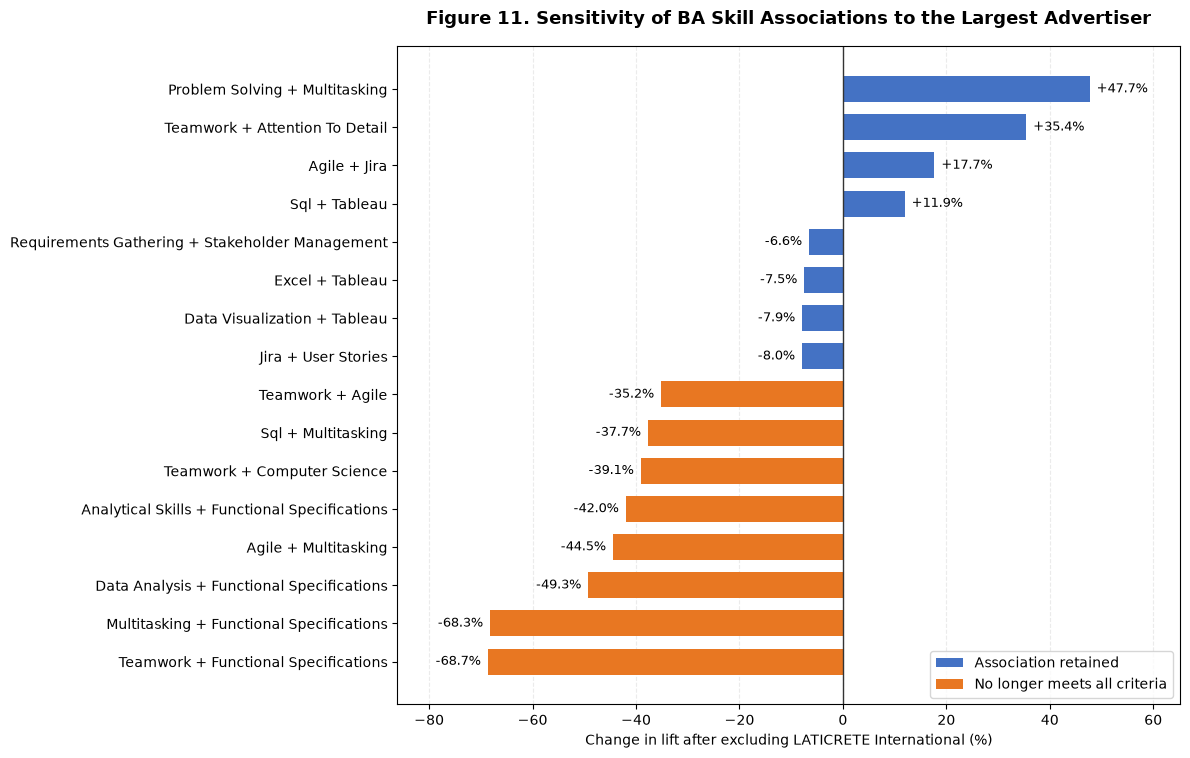

Figure 11 saved successfully.


In [9]:

# ============================================================
# RQ3 - STEP 6.3E: ASSOCIATION ROBUSTNESS VISUALISATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Select originally significant positive pairs
baseline_positive = (
    comparison["Holm_Significant"]
    & comparison["Lift"].gt(1)
    & comparison["Support_Pct"].ge(2)
)

robustness_plot = comparison.loc[
    baseline_positive
].copy()

# 2. Select largest percentage changes
robustness_plot["Absolute_Change_Pct"] = (
    robustness_plot["Lift_Change_Pct"].abs()
)

largest_changes = (
    robustness_plot
    .sort_values("Absolute_Change_Pct", ascending=False)
    .head(10)
)

# 3. Include important interpretable associations
key_pairs = [
    frozenset(["data visualization", "tableau"]),
    frozenset(["excel", "tableau"]),
    frozenset(["jira", "user stories"]),
    frozenset(["sql", "tableau"]),
    frozenset(["agile", "jira"]),
    frozenset([
        "requirements gathering",
        "stakeholder management"
    ])
]

key_associations = robustness_plot.loc[
    robustness_plot.apply(
        lambda r: frozenset([
            r["Skill_A"], r["Skill_B"]
        ]) in key_pairs,
        axis=1
    )
]

plot_df = pd.concat(
    [largest_changes, key_associations]
).drop_duplicates(
    subset=["Skill_A", "Skill_B"]
)

plot_df = plot_df.sort_values(
    "Lift_Change_Pct"
).reset_index(drop=True)

plot_df["Pair"] = (
    plot_df["Skill_A"].str.title()
    + " + "
    + plot_df["Skill_B"].str.title()
)

# 4. Determine which associations remain significant
plot_df["Retained"] = (
    plot_df["Robust_Significant"]
    & plot_df["Robust_Lift"].gt(1)
    & plot_df["Robust_Support_Pct"].ge(2)
)

# 5. Plot percentage change in lift
fig, ax = plt.subplots(
    figsize=(12, max(7, len(plot_df) * 0.48))
)

colors = np.where(
    plot_df["Retained"],
    "#4472C4",
    "#E87722"
)

bars = ax.barh(
    plot_df["Pair"],
    plot_df["Lift_Change_Pct"],
    color=colors,
    height=0.68
)

ax.axvline(
    0,
    color="#333333",
    linewidth=1
)

ax.set_xlabel(
    "Change in lift after excluding LATICRETE International (%)"
)

ax.set_title(
    "Figure 11. Sensitivity of BA Skill Associations "
    "to the Largest Advertiser",
    fontsize=13,
    fontweight="bold",
    pad=16
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# 6. Add percentage labels
for bar, value in zip(
    bars,
    plot_df["Lift_Change_Pct"]
):
    ax.annotate(
        f"{value:+.1f}%",
        xy=(
            value,
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9
    )

# 7. Legend
from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(
            facecolor="#4472C4",
            label="Association retained"
        ),
        Patch(
            facecolor="#E87722",
            label="No longer meets all criteria"
        )
    ],
    loc="lower right"
)

ax.margins(x=0.15)

plt.tight_layout()

# 8. Save
figure_path = (
    OUTPUT_DIR / "RQ3_Figure_11_Association_Robustness.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plot_df.to_csv(
    OUTPUT_DIR / "RQ3_FIGURE_11_ROBUSTNESS_DATA.csv",
    index=False
)

print("Figure 11 saved successfully.")


In [10]:

# ============================================================
# RQ3 - STEP 6.3F: TOP-FIVE ADVERTISER ROBUSTNESS CHECK
# ============================================================

import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

# 1. Identify the top five advertisers from the actual dataset
company_counts = (
    company_lookup.groupby("company")["job_link"]
    .nunique()
    .sort_values(ascending=False)
)

top_five = company_counts.head(5).index.tolist()

excluded_links_top5 = set(
    company_lookup.loc[
        company_lookup["company"].isin(top_five),
        "job_link"
    ]
)

# 2. Exclude their advertisements from the skills matrix
top5_matrix = skill_matrix.loc[
    ~skill_matrix.index.isin(excluded_links_top5)
].copy()

n_top5 = len(top5_matrix)

print("=" * 65)
print("RQ3 - TOP-FIVE ADVERTISER ROBUSTNESS")
print("=" * 65)

print("Excluded advertisers:")
for name in top_five:
    print("-", name)

print("\nOriginal skills-covered advertisements:", len(skill_matrix))
print("Excluded skills-covered advertisements:", len(skill_matrix) - n_top5)
print("Remaining skills-covered advertisements:", n_top5)

# 3. Recalculate support, lift and Fisher p-values
records = []

for a_name, b_name in combinations(top_skills, 2):
    a = top5_matrix[a_name].astype(bool)
    b = top5_matrix[b_name].astype(bool)

    count_a = int(a.sum())
    count_b = int(b.sum())
    count_ab = int((a & b).sum())

    support = count_ab / n_top5

    lift = (
        count_ab * n_top5 / (count_a * count_b)
        if count_a and count_b else np.nan
    )

    contingency = [
        [count_ab, count_a - count_ab],
        [count_b - count_ab,
         n_top5 - count_a - count_b + count_ab]
    ]

    _, p_value = fisher_exact(
        contingency,
        alternative="two-sided"
    )

    records.append({
        "Skill_A": a_name,
        "Skill_B": b_name,
        "Top5_Count": count_ab,
        "Top5_Support_Pct": support * 100,
        "Top5_Lift": lift,
        "Top5_P": p_value
    })

top5_results = pd.DataFrame(records)

# 4. Holm correction across all 435 pairs
reject, adjusted_p, _, _ = multipletests(
    top5_results["Top5_P"],
    alpha=0.05,
    method="holm"
)

top5_results["Top5_Holm_P"] = adjusted_p
top5_results["Top5_Significant"] = reject

# 5. Combine all three scenarios
three_scenarios = comparison.merge(
    top5_results,
    on=["Skill_A", "Skill_B"],
    validate="one_to_one"
)

baseline_valid = (
    three_scenarios["Holm_Significant"]
    & three_scenarios["Lift"].gt(1)
    & three_scenarios["Support_Pct"].ge(2)
)

largest_valid = (
    three_scenarios["Robust_Significant"]
    & three_scenarios["Robust_Lift"].gt(1)
    & three_scenarios["Robust_Support_Pct"].ge(2)
)

top5_valid = (
    three_scenarios["Top5_Significant"]
    & three_scenarios["Top5_Lift"].gt(1)
    & three_scenarios["Top5_Support_Pct"].ge(2)
)

print("\nROBUSTNESS COMPARISON")
print("Original significant positive pairs:", int(baseline_valid.sum()))
print("Retained after largest excluded:",
      int((baseline_valid & largest_valid).sum()))
print("Retained after top five excluded:",
      int((baseline_valid & top5_valid).sum()))
print("Retained in all three scenarios:",
      int((baseline_valid & largest_valid & top5_valid).sum()))

# 6. Compare strongest original associations
top20 = (
    three_scenarios.loc[baseline_valid]
    .sort_values("Lift", ascending=False)
    .head(20)
    .copy()
)

top20["Top5_Retained"] = top5_valid.loc[top20.index].to_numpy()

print("\nTOP 20 ORIGINAL ASSOCIATIONS ACROSS THREE SCENARIOS:")

display(
    top20[
        [
            "Skill_A",
            "Skill_B",
            "Lift",
            "Robust_Lift",
            "Top5_Lift",
            "Support_Pct",
            "Top5_Support_Pct",
            "Top5_Retained"
        ]
    ].round(3)
)

# 7. Save results
three_scenarios.to_csv(
    OUTPUT_DIR / "RQ3_THREE_SCENARIO_ROBUSTNESS.csv",
    index=False
)

print("\nThree-scenario robustness analysis saved.")


RQ3 - TOP-FIVE ADVERTISER ROBUSTNESS
Excluded advertisers:
- LATICRETE International
- Dice
- Tata Consultancy Services
- Stellent IT
- NR Consulting

Original skills-covered advertisements: 3606
Excluded skills-covered advertisements: 629
Remaining skills-covered advertisements: 2977

ROBUSTNESS COMPARISON
Original significant positive pairs: 92
Retained after largest excluded: 70
Retained after top five excluded: 65
Retained in all three scenarios: 64

TOP 20 ORIGINAL ASSOCIATIONS ACROSS THREE SCENARIOS:


,Skill_A,Skill_B,Lift,Robust_Lift,Top5_Lift,Support_Pct,Top5_Support_Pct,Top5_Retained
430,data visualization,tableau,6.072,5.591,5.300,3.466,3.964,True
236,teamwork,multitasking,4.061,3.170,2.960,5.324,1.814,False
406,multitasking,functional specifications,3.541,1.124,1.142,2.135,0.235,False
342,excel,tableau,3.510,3.246,3.137,2.662,3.158,True
324,jira,user stories,3.257,2.998,3.274,2.690,3.057,True
173,analytical skills,multitasking,3.027,2.346,2.305,5.186,1.948,False
157,sql,tableau,2.879,3.223,3.171,5.435,6.114,True
340,excel,data visualization,2.830,2.607,2.526,2.219,2.654,True
302,documentation,testing,2.679,2.741,2.984,2.634,2.452,True
248,agile,jira,2.317,2.727,2.743,3.439,3.628,True



Three-scenario robustness analysis saved.


In [11]:

# ============================================================
# RQ3 - STEP 6.4A: FP-GROWTH FREQUENT ITEMSET MINING
# ============================================================

# Install mlxtend if necessary (run separately):
# %pip install mlxtend

import pandas as pd
import numpy as np

from mlxtend.frequent_patterns import fpgrowth

# ------------------------------------------------------------
# 1. Prepare the transaction matrix
# ------------------------------------------------------------

# Reuse the existing skills matrix from RQ3
# Each row represents one advertisement.
# Each column represents one skill.
# True means the advertisement mentions that skill.

fp_matrix = skill_matrix.copy()

# Ensure Boolean values
fp_matrix = fp_matrix.astype(bool)

print("=" * 65)
print("RQ3 - FP-GROWTH FREQUENT ITEMSET MINING")
print("=" * 65)

print("Advertisements analysed:", len(fp_matrix))
print("Skills included:", fp_matrix.shape[1])

assert len(fp_matrix) == 3606, (
    "Unexpected number of advertisements. "
    "Check the existing skill matrix."
)

assert fp_matrix.shape[1] == 30, (
    "Expected the same 30 skills used in pairwise analysis."
)

# ------------------------------------------------------------
# 2. Run FP-Growth
# ------------------------------------------------------------

MIN_SUPPORT = 0.02
MAX_ITEMSET_LENGTH = 3

frequent_itemsets = fpgrowth(
    fp_matrix,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_ITEMSET_LENGTH
)

# ------------------------------------------------------------
# 3. Prepare readable results
# ------------------------------------------------------------

frequent_itemsets["Itemset_Size"] = (
    frequent_itemsets["itemsets"].apply(len)
)

frequent_itemsets["Skills"] = (
    frequent_itemsets["itemsets"].apply(
        lambda items: " + ".join(sorted(items))
    )
)

frequent_itemsets["Support_Pct"] = (
    frequent_itemsets["support"] * 100
)

frequent_itemsets["Advertisements"] = (
    np.rint(
        frequent_itemsets["support"] * len(fp_matrix)
    ).astype(int)
)

frequent_itemsets = frequent_itemsets.sort_values(
    ["Itemset_Size", "support"],
    ascending=[True, False]
).reset_index(drop=True)

# ------------------------------------------------------------
# 4. Summary
# ------------------------------------------------------------

print("\nFREQUENT ITEMSET SUMMARY")

itemset_summary = (
    frequent_itemsets
    .groupby("Itemset_Size")
    .agg(
        Itemsets=("Skills", "count"),
        Mean_Support_Pct=("Support_Pct", "mean"),
        Maximum_Support_Pct=("Support_Pct", "max")
    )
    .reset_index()
)

display(itemset_summary.round(3))

# ------------------------------------------------------------
# 5. Top three-skill combinations
# ------------------------------------------------------------

three_skill_itemsets = (
    frequent_itemsets.loc[
        frequent_itemsets["Itemset_Size"] == 3
    ]
    .sort_values(
        "support",
        ascending=False
    )
)

print("\nTOP 20 THREE-SKILL COMBINATIONS")

display(
    three_skill_itemsets[
        [
            "Skills",
            "Advertisements",
            "Support_Pct"
        ]
    ].head(20).round(3)
)

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

frequent_itemsets[
    [
        "Skills",
        "Itemset_Size",
        "Advertisements",
        "Support_Pct"
    ]
].to_csv(
    OUTPUT_DIR / "RQ3_FP_GROWTH_FREQUENT_ITEMSETS.csv",
    index=False
)

print("\nFP-Growth results saved successfully.")


RQ3 - FP-GROWTH FREQUENT ITEMSET MINING
Advertisements analysed: 3606
Skills included: 30

FREQUENT ITEMSET SUMMARY


,Itemset_Size,Itemsets,Mean_Support_Pct,Maximum_Support_Pct
0,1,30,14.782,40.904
1,2,197,4.468,17.499
2,3,165,3.098,8.514



TOP 20 THREE-SKILL COMBINATIONS


,Skills,Advertisements,Support_Pct
227,communication + problem solving + project mana...,307,8.514
228,business analysis + communication + problem so...,303,8.403
229,business analysis + communication + project ma...,292,8.098
230,communication + data analysis + problem solving,290,8.042
231,business analysis + problem solving + project ...,253,7.016
232,communication + data analysis + project manage...,247,6.850
233,business analysis + data analysis + project ma...,238,6.600
234,data analysis + problem solving + project mana...,231,6.406
235,business analysis + communication + data analysis,218,6.045
236,business analysis + data analysis + problem so...,206,5.713



FP-Growth results saved successfully.


In [12]:

import pandas as pd
from mlxtend.frequent_patterns import fpgrowth, association_rules
from IPython.display import display

# ============================================================
# RQ3 - STEP 6.4B: FORMAL ASSOCIATION RULE MINING
# ============================================================

# Recreate frequent itemsets from the existing skill matrix
# using the same 2% minimum support as Step 6.4A.

fp_matrix = skill_matrix.astype(bool)

frequent_itemsets = fpgrowth(
    fp_matrix,
    min_support=0.02,
    use_colnames=True,
    max_len=3
)

# Generate directional association rules
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.20
)

# Apply interpretable filtering criteria
rules = rules[
    (rules["support"] >= 0.02) &
    (rules["confidence"] >= 0.20) &
    (rules["lift"] > 1)
].copy()

# Convert skill sets into readable strings
def format_skillset(items):
    return " + ".join(sorted(items))

rules["Antecedent"] = rules["antecedents"].apply(format_skillset)
rules["Consequent"] = rules["consequents"].apply(format_skillset)

rules["Antecedent_Size"] = rules["antecedents"].apply(len)
rules["Consequent_Size"] = rules["consequents"].apply(len)

rules["Support_Pct"] = rules["support"] * 100
rules["Confidence_Pct"] = rules["confidence"] * 100

rules["Advertisements"] = (
    rules["support"] * len(fp_matrix)
).round().astype(int)

# Sort strongest rules by lift, then confidence
rules = rules.sort_values(
    ["lift", "confidence", "support"],
    ascending=False
).reset_index(drop=True)

# Prepare readable results
rule_summary = rules[
    [
        "Antecedent",
        "Consequent",
        "Advertisements",
        "Support_Pct",
        "Confidence_Pct",
        "lift",
        "Antecedent_Size",
        "Consequent_Size"
    ]
].rename(columns={"lift": "Lift"})

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("=" * 65)
print("RQ3 - FORMAL ASSOCIATION RULE MINING")
print("=" * 65)

print("Advertisements analysed:", len(fp_matrix))
print("Frequent itemsets:", len(frequent_itemsets))
print("Association rules retained:", len(rules))

print("\nTOP 20 ASSOCIATION RULES BY LIFT:")
display(rule_summary.head(20).round(3))

print("\nTOP 20 ASSOCIATION RULES BY CONFIDENCE:")
display(
    rule_summary.sort_values(
        ["Confidence_Pct", "Lift"],
        ascending=False
    ).head(20).round(3)
)

print("\nRULE STRUCTURE:")
display(
    rule_summary.groupby(
        ["Antecedent_Size", "Consequent_Size"]
    ).size().reset_index(name="Rules")
)

# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------

rule_summary.to_csv(
    OUTPUT_DIR / "RQ3_ASSOCIATION_RULES.csv",
    index=False
)

frequent_itemsets.to_csv(
    OUTPUT_DIR / "RQ3_FP_GROWTH_ITEMSETS.csv",
    index=False
)

print("\nAssociation rule results saved successfully.")


RQ3 - FORMAL ASSOCIATION RULE MINING
Advertisements analysed: 3606
Frequent itemsets: 392
Association rules retained: 738

TOP 20 ASSOCIATION RULES BY LIFT:


,Antecedent,Consequent,Advertisements,Support_Pct,Confidence_Pct,Lift,Antecedent_Size,Consequent_Size
0,data visualization + sql,tableau,103,2.856,65.190,8.771,2,1
1,tableau,data visualization + sql,103,2.856,38.433,8.771,1,2
2,multitasking,analytical skills + teamwork,149,4.132,50.168,7.236,1,2
3,analytical skills + teamwork,multitasking,149,4.132,59.600,7.236,2,1
4,sql + tableau,data visualization,103,2.856,52.551,6.841,2,1
5,data visualization,sql + tableau,103,2.856,37.184,6.841,1,2
6,data analysis + tableau,data visualization,80,2.219,50.314,6.550,2,1
7,data visualization,data analysis + tableau,80,2.219,28.881,6.550,1,2
8,excel + sql,tableau,74,2.052,46.541,6.262,2,1
9,tableau,excel + sql,74,2.052,27.612,6.262,1,2



TOP 20 ASSOCIATION RULES BY CONFIDENCE:


,Antecedent,Consequent,Advertisements,Support_Pct,Confidence_Pct,Lift,Antecedent_Size,Consequent_Size
49,data visualization + tableau,sql,103,2.856,82.400,3.244,2,1
16,multitasking + sql,teamwork,86,2.385,81.905,5.145,2,1
19,data analysis + multitasking,teamwork,133,3.688,80.120,5.033,2,1
21,analytical skills + multitasking,teamwork,149,4.132,79.679,5.006,2,1
59,attention to detail + communication,problem solving,107,2.967,79.259,2.934,2,1
54,data analysis + tableau,sql,126,3.494,79.245,3.120,2,1
80,collaboration + problem solving,communication,148,4.104,77.895,2.628,2,1
28,multitasking + teamwork,analytical skills,149,4.132,77.604,3.731,2,1
83,problem solving + stakeholder management,communication,98,2.718,77.165,2.603,2,1
55,excel + tableau,sql,74,2.052,77.083,3.035,2,1



RULE STRUCTURE:


,Antecedent_Size,Consequent_Size,Rules
0,1,1,196
1,1,2,123
2,2,1,419



Association rule results saved successfully.


C:\Users\Dell\AppData\Local\Temp\ipykernel_692\2446005325.py:108: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  comparison = original_rules.join(


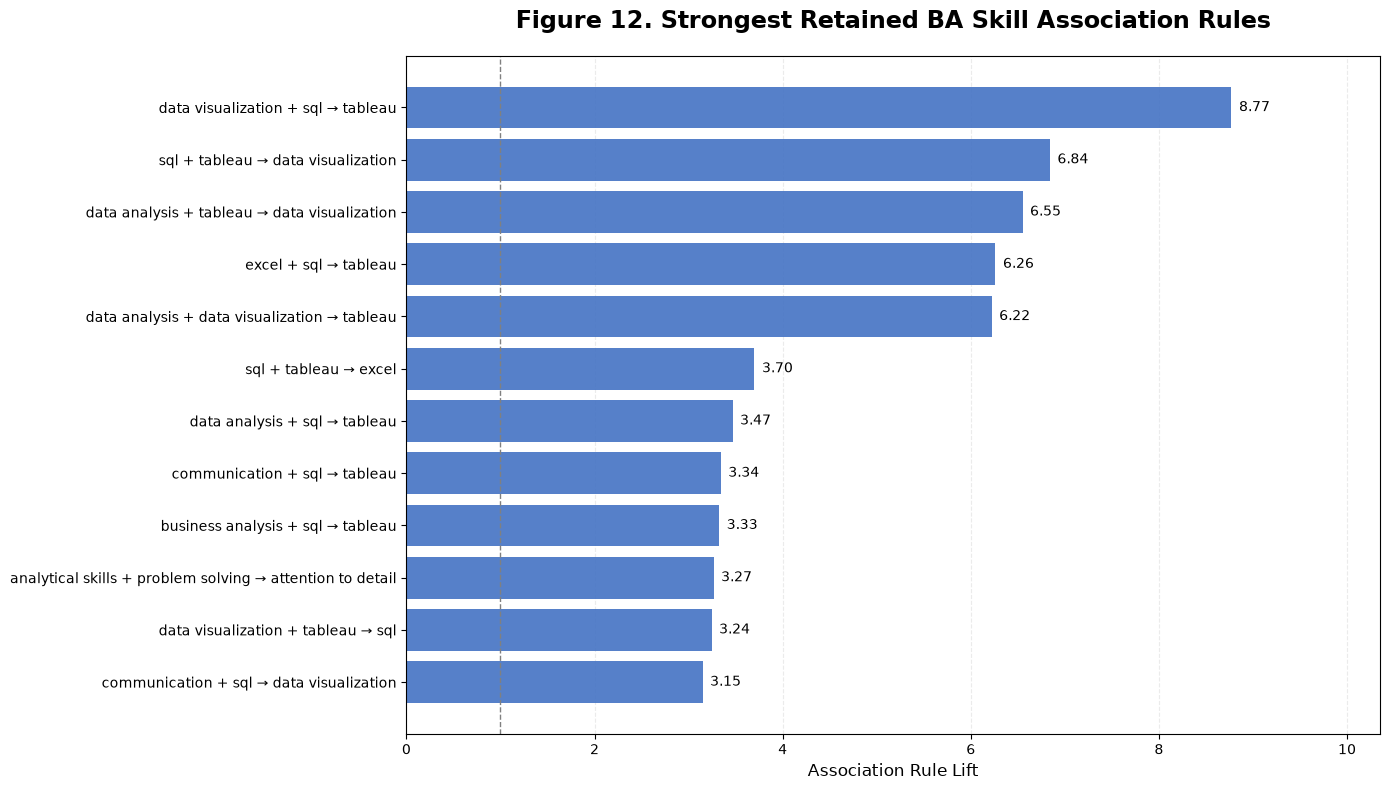

RQ3 - ASSOCIATION RULE ROBUSTNESS
Original advertisements: 3606
After largest advertiser excluded: 3310
Original 2-to-1 rules: 419
Retained rules: 347

TOP RETAINED RULES:


,Rule,support,confidence,lift,lift_Robust,Lift_Change_Pct
686,data visualization + sql → tableau,0.029,0.652,8.771,8.084,-7.833
687,sql + tableau → data visualization,0.029,0.526,6.841,6.305,-7.830
691,data analysis + tableau → data visualization,0.022,0.503,6.550,6.035,-7.869
704,excel + sql → tableau,0.021,0.465,6.262,5.791,-7.518
692,data analysis + data visualization → tableau,0.022,0.462,6.222,5.715,-8.143
705,sql + tableau → excel,0.021,0.378,3.700,3.431,-7.262
682,data analysis + sql → tableau,0.035,0.258,3.467,4.274,23.284
700,communication + sql → tableau,0.021,0.248,3.342,3.596,7.602
697,business analysis + sql → tableau,0.024,0.247,3.325,3.157,-5.063
249,analytical skills + problem solving → attentio...,0.022,0.297,3.265,3.322,1.736



Figure 12 and robustness results saved.


In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import fpgrowth, association_rules

# ============================================================
# RQ3 - STEP 6.4C: ASSOCIATION RULE VISUALISATION
# AND LARGEST-ADVERTISER ROBUSTNESS
# ============================================================

# 1. Recreate the original frequent itemsets and rules
original_matrix = skill_matrix.astype(bool)

original_itemsets = fpgrowth(
    original_matrix,
    min_support=0.02,
    use_colnames=True,
    max_len=3
)

original_rules = association_rules(
    original_itemsets,
    metric="confidence",
    min_threshold=0.20
)

original_rules = original_rules[
    (original_rules["support"] >= 0.02) &
    (original_rules["confidence"] >= 0.20) &
    (original_rules["lift"] > 1) &
    (original_rules["antecedents"].apply(len) == 2) &
    (original_rules["consequents"].apply(len) == 1)
].copy()

def readable(items):
    return " + ".join(sorted(items))

original_rules["Antecedent"] = (
    original_rules["antecedents"].apply(readable)
)
original_rules["Consequent"] = (
    original_rules["consequents"].apply(readable)
)
original_rules["Rule"] = (
    original_rules["Antecedent"]
    + " → "
    + original_rules["Consequent"]
)

# 2. Identify advertisements belonging to largest advertiser
jobs = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv",
    usecols=["job_link", "company"]
)

largest_advertiser = "LATICRETE International"

excluded_links = set(
    jobs.loc[
        jobs["company"].fillna("").str.strip()
        == largest_advertiser,
        "job_link"
    ]
)

# 3. Create advertiser-excluded skill matrix
robust_matrix = original_matrix.loc[
    ~original_matrix.index.isin(excluded_links)
].copy()

# 4. Recalculate rules after exclusion
robust_itemsets = fpgrowth(
    robust_matrix,
    min_support=0.02,
    use_colnames=True,
    max_len=3
)

robust_rules = association_rules(
    robust_itemsets,
    metric="confidence",
    min_threshold=0.20
)

robust_rules = robust_rules[
    (robust_rules["support"] >= 0.02) &
    (robust_rules["confidence"] >= 0.20) &
    (robust_rules["lift"] > 1) &
    (robust_rules["antecedents"].apply(len) == 2) &
    (robust_rules["consequents"].apply(len) == 1)
].copy()

# Match rules using their exact skill sets
original_rules["Rule_Key"] = list(zip(
    original_rules["antecedents"],
    original_rules["consequents"]
))

robust_rules["Rule_Key"] = list(zip(
    robust_rules["antecedents"],
    robust_rules["consequents"]
))

robust_lookup = robust_rules.set_index("Rule_Key")[
    ["lift", "confidence", "support"]
]

comparison = original_rules.join(
    robust_lookup,
    on="Rule_Key",
    rsuffix="_Robust"
)

comparison["Retained"] = comparison["lift_Robust"].notna()

comparison["Lift_Change_Pct"] = (
    (comparison["lift_Robust"] - comparison["lift"])
    / comparison["lift"] * 100
)

# 5. Select strongest rules that remain retained
plot_data = (
    comparison[comparison["Retained"]]
    .sort_values(
        ["lift", "confidence"],
        ascending=False
    )
    .head(12)
    .sort_values("lift", ascending=True)
    .copy()
)

# 6. Create Figure 12
fig, ax = plt.subplots(figsize=(14, 8))

bars = ax.barh(
    plot_data["Rule"],
    plot_data["lift"],
    color="#4472C4",
    alpha=0.90
)

for bar, value in zip(bars, plot_data["lift"]):
    ax.text(
        value + 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        fontsize=10
    )

ax.set_xlabel("Association Rule Lift", fontsize=12)
ax.set_ylabel("")

ax.set_title(
    "Figure 12. Strongest Retained BA Skill Association Rules",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.axvline(1, color="gray", linestyle="--", linewidth=1)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.set_xlim(0, max(plot_data["lift"]) * 1.18)

plt.tight_layout()

figure_path = (
    OUTPUT_DIR / "RQ3_Figure_12_Association_Rules.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Print robustness summary
print("=" * 65)
print("RQ3 - ASSOCIATION RULE ROBUSTNESS")
print("=" * 65)

print("Original advertisements:", len(original_matrix))
print("After largest advertiser excluded:", len(robust_matrix))
print("Original 2-to-1 rules:", len(original_rules))
print("Retained rules:", comparison["Retained"].sum())

print("\nTOP RETAINED RULES:")
display(
    plot_data[
        [
            "Rule",
            "support",
            "confidence",
            "lift",
            "lift_Robust",
            "Lift_Change_Pct"
        ]
    ].sort_values("lift", ascending=False).round(3)
)

comparison[
    [
        "Rule",
        "support",
        "confidence",
        "lift",
        "lift_Robust",
        "Lift_Change_Pct",
        "Retained"
    ]
].to_csv(
    OUTPUT_DIR / "RQ3_ASSOCIATION_RULE_ROBUSTNESS.csv",
    index=False
)

print("\nFigure 12 and robustness results saved.")


In [14]:

import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import fpgrowth, association_rules
from IPython.display import display

# ============================================================
# RQ3 - STEP 6.4D
# TOP-FIVE ADVERTISER ASSOCIATION RULE ROBUSTNESS
# ============================================================

top_five = [
    "LATICRETE International",
    "Dice",
    "Tata Consultancy Services",
    "Stellent IT",
    "NR Consulting"
]

# 1. Load advertiser information
jobs = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv",
    usecols=["job_link", "company"]
)

jobs["company"] = jobs["company"].fillna("").str.strip()

excluded_links = set(
    jobs.loc[
        jobs["company"].isin(top_five),
        "job_link"
    ]
)

# 2. Use existing skill matrix
original_matrix = skill_matrix.astype(bool)

top5_matrix = original_matrix.loc[
    ~original_matrix.index.isin(excluded_links)
].copy()

# 3. Generate rules consistently in both datasets
def generate_rules(matrix):
    itemsets = fpgrowth(
        matrix,
        min_support=0.02,
        use_colnames=True,
        max_len=3
    )

    rules = association_rules(
        itemsets,
        metric="confidence",
        min_threshold=0.20
    )

    rules = rules[
        (rules["support"] >= 0.02) &
        (rules["confidence"] >= 0.20) &
        (rules["lift"] > 1) &
        (rules["antecedents"].apply(len) == 2) &
        (rules["consequents"].apply(len) == 1)
    ].copy()

    rules["Rule_Key"] = list(zip(
        rules["antecedents"],
        rules["consequents"]
    ))

    return rules

original_rules = generate_rules(original_matrix)
top5_rules = generate_rules(top5_matrix)

# 4. Match rules across datasets
top5_lookup = top5_rules.set_index("Rule_Key")[
    ["support", "confidence", "lift"]
]

comparison = original_rules.join(
    top5_lookup,
    on="Rule_Key",
    rsuffix="_Top5"
)

comparison["Retained_Top5"] = (
    comparison["lift_Top5"].notna()
)

comparison["Lift_Change_Pct"] = (
    (comparison["lift_Top5"] - comparison["lift"])
    / comparison["lift"] * 100
)

def readable(items):
    return " + ".join(sorted(items))

comparison["Rule"] = (
    comparison["antecedents"].apply(readable)
    + " → "
    + comparison["consequents"].apply(readable)
)

# 5. Check the 12 rules displayed in Figure 12
# Recreate the Figure 12 selection using largest-advertiser exclusion
largest_links = set(
    jobs.loc[
        jobs["company"].eq("LATICRETE International"),
        "job_link"
    ]
)

largest_matrix = original_matrix.loc[
    ~original_matrix.index.isin(largest_links)
]

largest_rules = generate_rules(largest_matrix)
largest_keys = set(largest_rules["Rule_Key"])

figure12_rules = (
    comparison[
        comparison["Rule_Key"].isin(largest_keys)
    ]
    .sort_values(
        ["lift", "confidence"],
        ascending=False
    )
    .head(12)
    .copy()
)

# 6. Display summary
print("=" * 65)
print("RQ3 - TOP-FIVE ADVERTISER RULE ROBUSTNESS")
print("=" * 65)

print("Original advertisements:", len(original_matrix))
print("Top-five excluded advertisements:",
      len(original_matrix) - len(top5_matrix))
print("Remaining advertisements:", len(top5_matrix))

print("\nOriginal 2-to-1 rules:", len(original_rules))
print("Rules retained after top-five exclusion:",
      comparison["Retained_Top5"].sum())

print("\nFIGURE 12 RULES - TOP-FIVE ROBUSTNESS:")

display(
    figure12_rules[
        [
            "Rule",
            "support",
            "confidence",
            "lift",
            "support_Top5",
            "confidence_Top5",
            "lift_Top5",
            "Lift_Change_Pct",
            "Retained_Top5"
        ]
    ].round(3)
)

print("\nFigure 12 rules retained:",
      figure12_rules["Retained_Top5"].sum(),
      "out of",
      len(figure12_rules))

# 7. Save results
comparison[
    [
        "Rule",
        "support",
        "confidence",
        "lift",
        "support_Top5",
        "confidence_Top5",
        "lift_Top5",
        "Lift_Change_Pct",
        "Retained_Top5"
    ]
].to_csv(
    OUTPUT_DIR / "RQ3_TOP5_ASSOCIATION_RULE_ROBUSTNESS.csv",
    index=False
)

print("\nTop-five robustness analysis saved successfully.")


RQ3 - TOP-FIVE ADVERTISER RULE ROBUSTNESS
Original advertisements: 3606
Top-five excluded advertisements: 629
Remaining advertisements: 2977

Original 2-to-1 rules: 419
Rules retained after top-five exclusion: 354

FIGURE 12 RULES - TOP-FIVE ROBUSTNESS:


C:\Users\Dell\AppData\Local\Temp\ipykernel_692\2749277201.py:79: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  comparison = original_rules.join(


,Rule,support,confidence,lift,support_Top5,confidence_Top5,lift_Top5,Lift_Change_Pct,Retained_Top5
686,data visualization + sql → tableau,0.029,0.652,8.771,0.033,0.647,7.639,-12.906,True
687,sql + tableau → data visualization,0.029,0.526,6.841,0.033,0.533,6.033,-11.815,True
691,data analysis + tableau → data visualization,0.022,0.503,6.550,0.025,0.497,5.621,-14.180,True
704,excel + sql → tableau,0.021,0.465,6.262,0.025,0.471,5.564,-11.153,True
692,data analysis + data visualization → tableau,0.022,0.462,6.222,0.025,0.448,5.291,-14.969,True
705,sql + tableau → excel,0.021,0.378,3.700,0.025,0.401,3.373,-8.825,True
682,data analysis + sql → tableau,0.035,0.258,3.467,0.039,0.352,4.155,19.833,True
700,communication + sql → tableau,0.021,0.248,3.342,0.025,0.298,3.516,5.210,True
697,business analysis + sql → tableau,0.024,0.247,3.325,0.027,0.263,3.107,-6.567,True
249,analytical skills + problem solving → attentio...,0.022,0.297,3.265,0.025,0.320,3.096,-5.169,True



Figure 12 rules retained: 12 out of 12

Top-five robustness analysis saved successfully.
